In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('titanic-train.csv', usecols=['Age', 'Fare', 'Survived'])

In [4]:
df.dropna(inplace=True)

In [5]:
df.shape

(714, 3)

In [6]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [7]:
df.sample(5)

,Survived,Age,Fare
275,1,63.0,77.9583
721,0,17.0,7.0542
412,1,33.0,90.0000
566,0,19.0,7.8958
623,0,21.0,7.8542


In [8]:
X = df.iloc[:, 1:]
y = df.iloc[:, 0]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [11]:
clf = DecisionTreeClassifier()

In [12]:
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

In [13]:
accuracy_score(y_test, y_pred)

0.6223776223776224

In [14]:
np.mean(cross_val_score(
    DecisionTreeClassifier(), X, y, cv=10, scoring='accuracy'
))

np.float64(0.6331377151799686)

In [18]:
from sklearn.preprocessing import KBinsDiscretizer

In [20]:
kbin_age = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')

In [21]:
trf = ColumnTransformer([
    ('first', kbin_age, [0]),
    ('second', kbin_fare, [1])
])

In [22]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [23]:
trf.named_transformers_['first'].n_bins_

array([10])

In [24]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42, 14.  , 19.  , 22.  , 25.  , 28.5 , 32.  , 36.  , 42.  ,
              50.  , 80.  ])                                                ],
      dtype=object)

In [25]:
trf.named_transformers_['second'].bin_edges_

array([array([  0.    ,   7.75  ,   7.8958,   9.225 ,  13.    ,  15.75  ,
               26.    ,  29.125 ,  51.4792,  82.1708, 512.3292])         ],
      dtype=object)

In [26]:
output = pd.DataFrame({
    'age': X_train['Age'],
    'age_trf': X_train_trf[:, 0],
    'fare': X_train['Fare'],
    'fare_trf': X_train_trf[:, 1]
})

In [27]:
output['age_labels'] = pd.cut(
    x=X_train['Age'],
    bins=trf.named_transformers_['first'].bin_edges_[0].tolist()
)

output['fare_labels'] = pd.cut(
    x=X_train['Fare'],
    bins=trf.named_transformers_['second'].bin_edges_[0].tolist()
)

In [28]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
183,1.0,0.0,39.000,7.0,"(0.42, 14.0]","(29.125, 51.479]"
119,2.0,0.0,31.275,7.0,"(0.42, 14.0]","(29.125, 51.479]"
112,22.0,3.0,8.050,2.0,"(19.0, 22.0]","(7.896, 9.225]"
600,24.0,3.0,27.000,6.0,"(22.0, 25.0]","(26.0, 29.125]"
585,18.0,1.0,79.650,8.0,"(14.0, 19.0]","(51.479, 82.171]"


In [29]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf, y_train)
y_pred2 = clf.predict(X_test_trf)

In [30]:
accuracy_score(y_test, y_pred2)

0.6223776223776224

In [31]:
X_trf = trf.fit_transform(X)

np.mean(cross_val_score(
    DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'
))

np.float64(0.6807316118935838)

In [33]:
def discretize(bins, strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)

    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])

    X_trf = trf.fit_transform(X)

    print(np.mean(cross_val_score(
        DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'
    )))

    plt.figure(figsize=(14, 4))

    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title('Before')

    plt.subplot(122)
    plt.hist(X_trf[:, 0], color='red')
    plt.title('After')

    plt.show()

0.6807316118935838


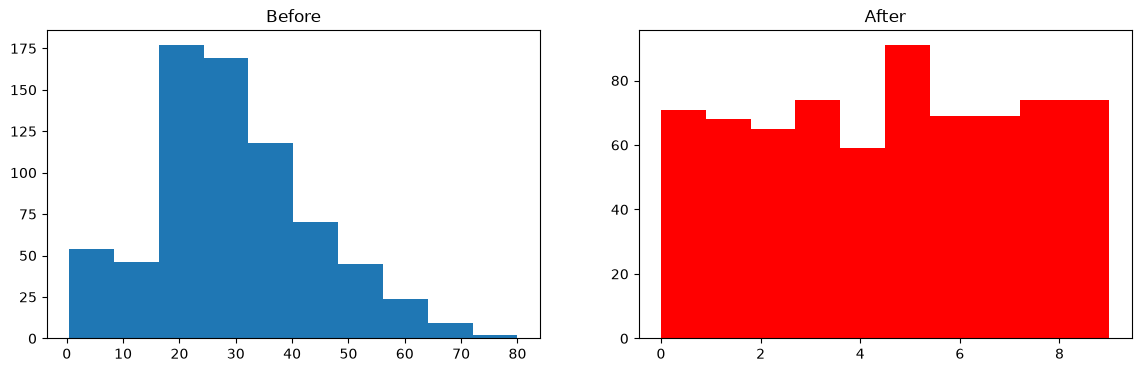

In [36]:
discretize(10,'quantile')

0.6864632237871675


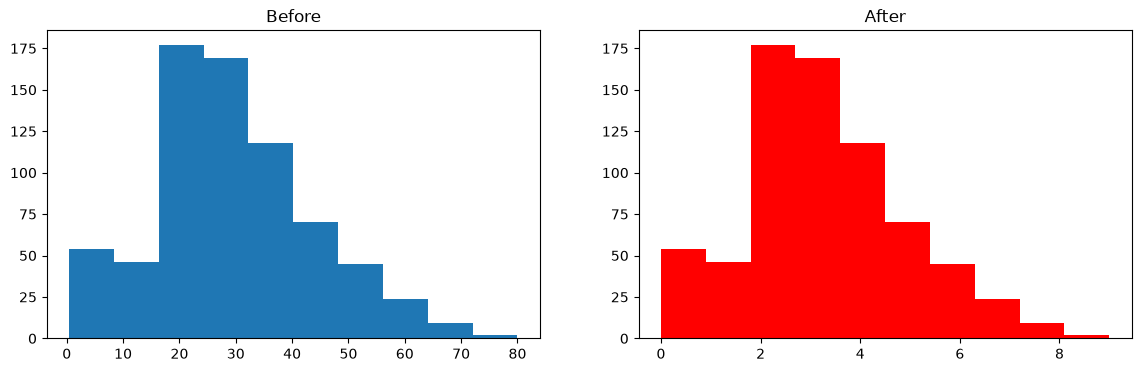

In [37]:
discretize(10,'uniform')

In [38]:
discretize(5,'Kmeans')

InvalidParameterError: The 'strategy' parameter of KBinsDiscretizer must be a str among {'kmeans', 'quantile', 'uniform'}. Got 'Kmeans' instead.